In [ ]:
#################################
# RUN ME FIRST TO LOAD FILES    #
#################################

!git clone https://github.com/GSU-Analytics/assessment

# Introduction

Welcome to the skill assessment notebook. These exercises evaluate your proficiency in SQL, Python, and data analysis.

You can skip questions without penalty. Use resources like Google, code samples, or AI tools, but be ready to discuss your answers and approach during the interview.

For questions, contact Isaac at ikerson@gsu.edu. Once finished, save the notebook and share the link with Isaac. We look forward to seeing your work!

# Overview of `university.db`

The `university.db` database is a mock SQLite database designed to simulate a collection of university data tables. It contains information about students, instructors, courses, grades, and more. This database is structured to provide realistic data for demonstrating data analysis skills.

## Database Schema

The database consists of the following tables:

### 1. **`student_main`**
- **Description**: Stores detailed information about students enrolled at the university.
- **Key Columns**:
  - `student_id`: Unique identifier for each student (primary key).
  - `last_name`, `first_name`, `middle_initial`: Student's name details.
  - `email`: Student's email address (not every student has one).
  - `gender`, `ethnicity`: Demographic information.
  - `address`, `us_citizen`, `us_resident`, `state_resident`: Residential and citizenship details. The citizen and resident columns are `Y` or `N`.
  - `pell_recipient`, `us_veteran`: Pell Grant recipient and veteran status, stored as `Y` or `N`.
- **Relationships**:
  - Linked to `student_grades` through `student_id`.
  - Linked to `student_attributes` through `student_id`.

### 2. **`instructor_main`**
- **Description**: Contains information about university instructors.
- **Key Columns**:
  - `employee_id`: Unique identifier for each instructor (primary key).
  - `last_name`, `first_name`: Instructor's name details.
  - `faculty_code`: Foreign key referencing `faculty_code_validation_table.faculty_code`, representing the faculty type (e.g., tenure-track, adjunct).
  - `full_time_indicator`: Binary indicator for full-time (1) or part-time (0) status.
- **Relationships**:
  - Linked to `courses` through `employee_id`.

### 3. **`faculty_code_validation_table`**
- **Description**: A lookup table that validates and describes faculty codes.
- **Key Columns**:
  - `faculty_code`: Three-letter code for faculty type (primary key).
  - `faculty_description`: Description of the faculty type.

### 4. **`courses`**
- **Description**: Represents the courses offered at the university.
- **Key Columns**:
  - `id`: Unique identifier for each course section (primary key).
  - `term_code`: Academic term as YYYYMM: `01` Spring, `05` Summer, `08` Fall (e.g., `202308` is Fall 2023).
  - `major_abbreviation`, `department_code`: Subject and department offering the course (e.g., MATH, BIO).
  - `course_number`, `section_code`: Course and section identifiers. A `section_code` is unique only within a term; the same code can appear in different terms.
  - `location_code`: Location where the course is held.
  - `delivery_code`: Mode of instruction (`I` In-person, `H` Hybrid, `O` Online).
  - `time`: Class start time (24-hour, e.g., `13:30`).
  - `monday` through `sunday`: 1 if the class meets that day, 0 otherwise.
  - `credits`: Number of credit hours assigned to the course (1–3).
  - `employee_id`: Foreign key referencing `instructor_main.employee_id`, indicating the instructor teaching the course.
- **Relationships**:
  - Linked to `instructor_main` through `employee_id`.
  - Linked to `student_grades` through `section_code` and `term_code`.

### 5. **`student_grades`**
- **Description**: Records students' grades for courses.
- **Key Columns**:
  - `id`: Unique identifier for each grade record (primary key).
  - `student_id`: Foreign key referencing `student_main.student_id`.
  - `term_code`: Term during which the grade was earned.
  - `section_code`: References `courses.section_code`; match on `term_code` as well.
  - `grade`: Grade points received for the course, from 0.0 to 4.0, stored as text. Missing when the student withdrew.
  - `withdrawal`: Binary indicator for course withdrawal (1 for withdrawal, 0 otherwise).
- **Relationships**:
  - Linked to `student_main` through `student_id`.
  - Linked to `courses` through `section_code` and `term_code`.

### 6. **`student_attributes`**
- **Description**: Tracks additional attributes assigned to students for specific terms.
- **Key Columns**:
  - `id`: Unique identifier for each attribute record (primary key).
  - `student_id`: Foreign key referencing `student_main.student_id`.
  - `term_code`: Academic term for which the attribute applies.
  - `attribute_code`: Foreign key referencing `attribute_code_validation_table.attribute_code`, indicating the assigned attribute (e.g., ESL, Honors).
- **Relationships**:
  - Linked to `student_main` through `student_id`.
  - Linked to `attribute_code_validation_table` through `attribute_code`.

### 7. **`attribute_code_validation_table`**
- **Description**: A lookup table that validates and describes student attribute codes.
- **Key Columns**:
  - `attribute_code`: Three-letter code for student attributes (primary key).
  - `attribute_description`: Description of the attribute.

## Relationships Between Tables

The tables and relationships in the `university.db` database detailed in the following schema diagram:

![University Database Schema](https://raw.githubusercontent.com/GSU-Analytics/assessment/main/schema_diagram.png)


### Introduction to Pandas and the `read_sql` Method

**Pandas** is a powerful Python library for data manipulation and analysis. It provides easy-to-use data structures like DataFrames and Series, which allow for efficient handling and processing of structured data. Pandas is widely used in data science, machine learning, and data analytics.

One of Pandas' strengths is its ability to seamlessly interact with SQL databases, enabling you to load query results directly into a DataFrame using the `read_sql` method. This method simplifies the process of querying databases and analyzing the results in Python.

#### What is `read_sql`?
The `pandas.read_sql()` method allows you to execute SQL queries on a database and retrieve the results as a Pandas DataFrame. It can be used to:
1. Query data from a database.
2. Load entire tables into a DataFrame.
3. Perform complex SQL queries and integrate results with Python-based analysis.

#### Basic Syntax
```python
pandas.read_sql(sql, con, index_col=None, coerce_float=True, params=None)
```

- **`sql`**: The SQL query or table name as a string.
- **`con`**: A database connection object (e.g., SQLAlchemy engine).
- **`index_col`**: Column(s) to set as the DataFrame index (optional).
- **`params`**: Parameters to pass for parameterized queries (optional).

#### Benefits of Using `read_sql`
- Directly integrates SQL querying into your Python workflow.
- Returns a DataFrame, which is ideal for further analysis and visualization in Python.
- Supports parameterized queries for added security and flexibility.

#### Documentation
For a complete guide to the `read_sql` method, visit the [Pandas Documentation](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_sql.html). 

This page provides detailed explanations, parameters, and examples to help you make the most of this method.

In [1]:
# Run the following cell for an example how to use `pd.read_sql`

import os
import pandas as pd
from sqlalchemy import create_engine

# Find the database: Colab clone, repository root, or the assessment folder
candidates = ["/content/assessment/university.db", "assessment/university.db", "university.db"]
DATABASE_FILE = next((p for p in candidates if os.path.exists(p)), None)
if DATABASE_FILE is None:
    raise FileNotFoundError("university.db not found. Run the first cell to clone the repository.")

# Define the database URL
DATABASE_URL = f"sqlite:///{DATABASE_FILE}"

# Create the engine to connect to the database
engine = create_engine(DATABASE_URL)

# Test the connection by running a query to get table names
query = "SELECT name FROM sqlite_master where type = 'table';"
tables = pd.read_sql(query, engine)

# Print the list of tables
print("Connected to the database!")
print("Tables in the database:")
display(tables)

Connected to the database!
Tables in the database:


,name
0,student_main
1,faculty_code_validation_table
2,attribute_code_validation_table
3,instructor_main
4,student_attributes
5,courses
6,student_grades


### Count the Total Number of Students

#### Directions:
Write a SQL query in the space provided below to count the total number of students in the database. Use the `student_main` table for this task. Then run the cell to execute your query and display the result.

In [2]:
## Complete the query to get the number of students in the `student_main` table
student_count_query = """
SELECT COUNT(DISTINCT student_id) AS student_count
FROM student_main;
"""

## Do not edit the code below
student_count_df = pd.read_sql(student_count_query, engine)

# Display the result
display(student_count_df)

,student_count
0,10000


### Get the Records of Pell Grant Recipients with an Email and a Last Name Starting with "A"

#### Directions:
Write a SQL query in the space provided below to retrieve the records of students who are Pell Grant recipients and have an email value as well a last name starting with the letter "A". Use the `student_main` table and filter on the `last_name`, `email`, and `pell_recipient` columns. Return the `student_id`, `last_name`, `first_name`, `email`, and `address` for each student. Then run the cell to execute your query and display the results.

In [ ]:
## Complete the query to get Pell Grant Recipients with a Last Name Starting with "A"
pell_grant_query = """
SELECT student_id, last_name, first_name, email, address
FROM student_main
WHERE pell_recipient = 'Y' AND email IS NOT NULL AND last_name LIKE 'A%';
"""

## Do not edit the code below
pell_grant_df = pd.read_sql(pell_grant_query, engine)

# Display the result
display(pell_grant_df.head())

,student_id,last_name,first_name,email,address
0,302872402,Andrews,Shelia,oleonard@example.com,"21977 Bailey Mills, Anthonybury, WA 20098"
1,940509385,Anderson,Richard,edward00@example.net,"00374 Fischer Field, Zacharyberg, AZ 22953"
2,742183361,Aguilar,Denise,nicole95@example.com,"974 Deborah Crossroad, Port Albertchester, KY ..."
3,503843010,Anderson,Cynthia,danielle45@example.org,"68356 Stone Camp, Port Bethanyburgh, WY 28778"
4,691270771,Ali,Lisa,ysims@example.com,"35874 Michelle Path Apt. 706, East Anna, AK 48323"


### Get the Average Credits per Student in Each Term

#### Directions:
Write a SQL query in the space provided below to calculate, for each term, the average number of credits a student took. First total each student's credits in the term, then average those totals across students. Use the `student_grades` and `courses` tables. Return `term_code` and `average_credits`, ordered by `term_code`. Then run the cell to execute your query and display the result.

In [30]:
## Complete the query to get the average credits per student in each term
average_credits_query = """
WITH student_term_credits AS (
    SELECT sg.student_id, sg.term_code, SUM(c.credits) AS total_credits
    FROM student_grades AS sg JOIN courses AS c ON sg.section_code = c.section_code AND sg.term_code = c.term_code
    GROUP BY sg.student_id, sg.term_code
)
SELECT term_code, AVG(total_credits) AS average_credits
FROM student_term_credits
GROUP BY term_code
ORDER BY term_code ASC;
"""

## Do not edit the code below
average_credits_df = pd.read_sql(average_credits_query, engine)

# Display the result
display(average_credits_df)

,term_code,average_credits
0,201901,6.494505
1,201905,6.524377
2,201908,5.956522
3,202001,6.251951
4,202005,6.201525
5,202008,6.278602
6,202101,6.396721
7,202105,5.476489
8,202108,6.448037
9,202201,5.973176


## Create a Bar Plot of Average Credits Over Time

#### Directions:
Using the results from the previous query, create a bar plot showing the average credits per student over time. The x-axis should represent the term code, and the y-axis should display the average credits per student. Label the axes appropriately and provide a title for the plot. You can use any Python data visualization library you prefer (e.g., Matplotlib, Seaborn, etc.).

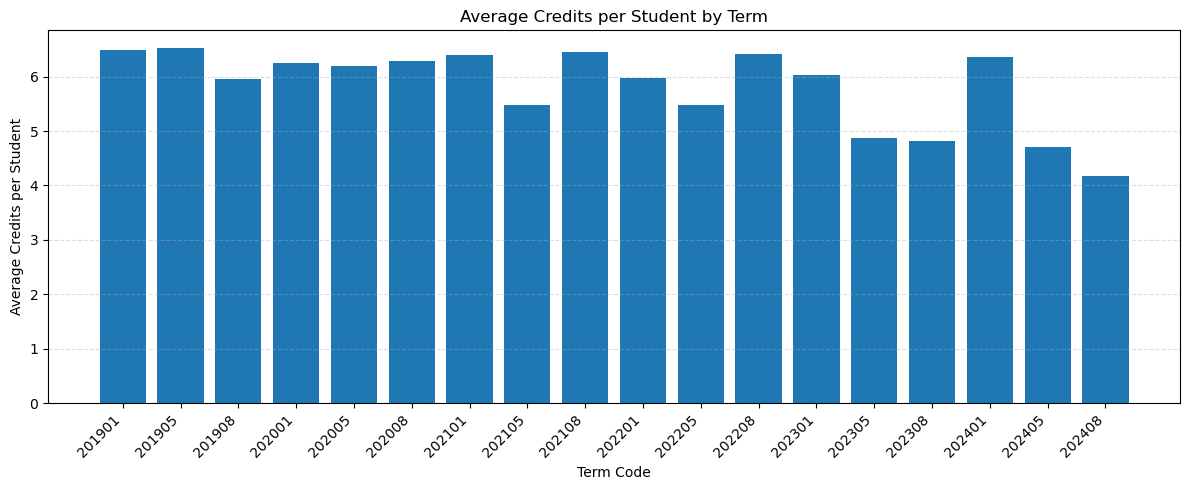

In [259]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.bar(average_credits_df['term_code'].astype(str), average_credits_df['average_credits'], color='tab:blue')
plt.title('Average Credits per Student by Term')
plt.xlabel('Term Code')
plt.ylabel('Average Credits per Student')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


# Open-ended Analysis

### Directions

In this section, please explore the `university.db` database and conduct any additional analyses you find interesting. This is an opportunity to showcase your skills, creativity, and analytical thinking. Feel free to ask questions, propose new analyses, or present your findings in any format you prefer (e.g., tables, charts, written summaries).

You can use SQL queries, Python code, data visualizations, or any other tools you find suitable for the task. Your analysis can cover topics like student performance, course enrollment trends, faculty characteristics, or any other aspect of the university data.

### Possible Questions for Analysis

Below are some example questions you might explore. They are only suggestions. You are **not** obligated to answer all or any of them. Pick one or come up with your own question to answer.

#### Grade Analysis
- Are there particular **courses**, **instructors**, or **student populations** that have significant deviations in outcomes?
- How do **average grades** differ across terms, courses, or majors?
- What is the distribution of grades for students in honors (HNR) or English as a Second Language (ESL) programs?

#### Enrollment Patterns
- What are the **enrollment patterns** for courses by day and/or time?
- Which courses have the **highest or lowest enrollments** across all terms?
- How do enrollments differ across **delivery modes** (in-person, hybrid, online)?

#### Instructor Impact
- Do specific instructors have consistently **higher or lower average grades** in their courses?
- How do full-time versus part-time instructors differ in terms of course outcomes?

#### Term Trends
- Are there any **seasonal trends** in course enrollment or performance (e.g., spring vs. summer vs. fall)?
- What is the average number of courses taken by students in each term?

#### Student Demographics
- What percentage of students are enrolled in **honors** or **athletic programs** each term?
- How does student performance differ by **gender** or **ethnicity**?

#### Course Specific Analysis
- What is the **most common combination** of courses taken by students in a given term?
- How do **drop/withdrawal rates** vary by course, instructor, or term?

------

## Analysis Question: How do drop/withdrawals rates vary by course, instructor, term, day, and delivery mode?

Course withdrawals can have financial and operational impacts on universities. While enrollment projections help with planning course offerings and with allocating resources, withdrawals can result in tuition refunds and/or empty seats after resources have already been committed. Resources and funds might be wasted. Identifying withdrawal patterns could help universities better their planning decisions and recognize courses/periods where students struggle.

Withdrawal rates are calculated as the number of course registrations with a withdrawal indicator of 1 divided by the total number of course registrations, multiplied by 100.

### Baseline Withdrawal Rate

In [205]:
# Average Overall Withdrawal Rate Across All Registrations
overall_withdrawal_query = """
SELECT COUNT(*) AS total_registrations, SUM(withdrawal) AS total_withdrawals, ROUND(AVG(withdrawal) * 100.0, 2) AS average_withdrawal_rate
FROM student_grades
"""

overall_withdrawal_df = pd.read_sql(overall_withdrawal_query, engine)
display(overall_withdrawal_df)

,total_registrations,total_withdrawals,average_withdrawal_rate
0,50000,2497,4.99


Of 50,000 course registrations, 2,497 resulted in withdrawals, giving an overall withdrawal rate of 4.99%. This is a baseline for comparing withdrawal rates across different course characteristics.

### Temporal & Mode Analysis

This section examines how course withdrawal rates vary across academic and scheduling characteristics, including academic terms, seasonal enrollment periods, delivery modes, and scheduled class days.

,term_code,registrations,withdrawals,withdrawal_rate
0,201901,2749,138,5.02
1,201905,2768,135,4.88
2,201908,2750,136,4.95
3,202001,2642,133,5.03
4,202005,2840,144,5.07
5,202008,2826,126,4.46
6,202101,2803,163,5.82
7,202105,2853,129,4.52
8,202108,2647,130,4.91
9,202201,2781,144,5.18


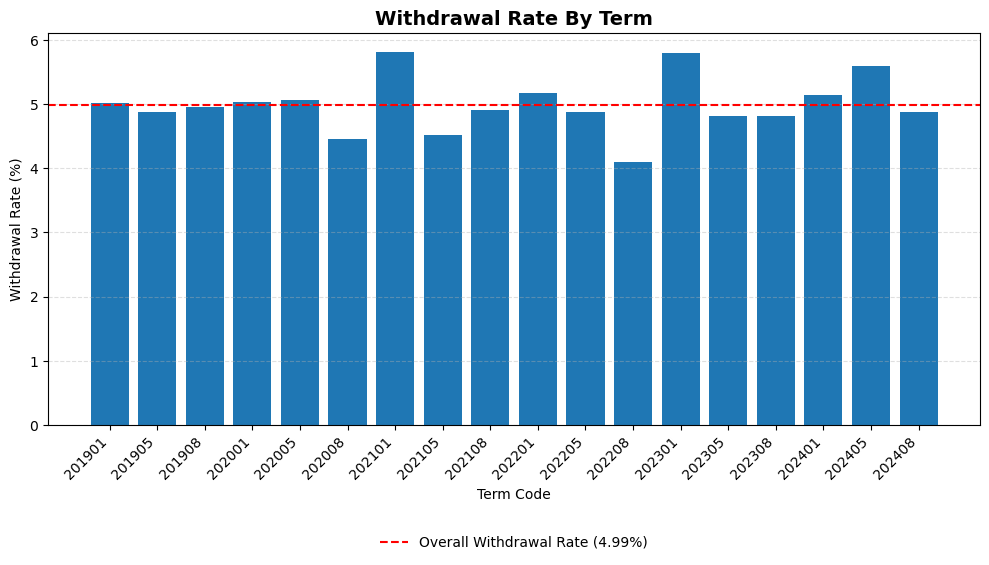

,term_code,registrations,withdrawals,withdrawal_rate,term_season
0,01,16668,889,5.33,Spring
1,05,16879,837,4.96,Summer
2,08,16453,771,4.69,Fall


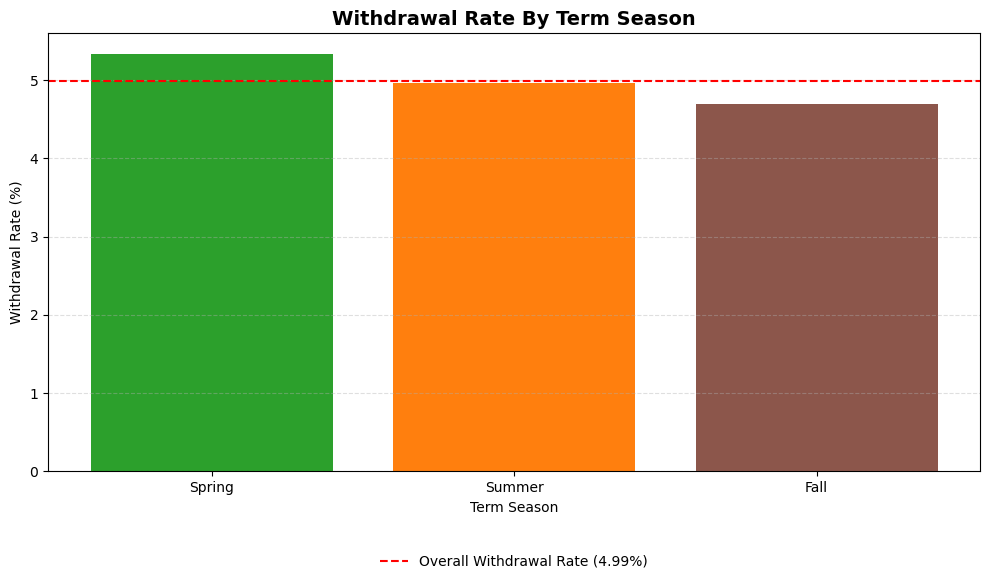

In [206]:
# Withdrawal Rate by Term
withdrawal_term_query = """
SELECT c.term_code, COUNT(*) AS registrations, SUM(sg.withdrawal) AS withdrawals, ROUND(AVG(sg.withdrawal) * 100.0, 2) AS withdrawal_rate
FROM student_grades AS sg
JOIN courses AS c ON sg.section_code = c.section_code AND sg.term_code = c.term_code
GROUP BY c.term_code
ORDER BY c.term_code;
"""

withdrawal_term_df = pd.read_sql(withdrawal_term_query, engine)
display(withdrawal_term_df)

plt.figure(figsize=(10, 6))
plt.bar(withdrawal_term_df['term_code'].astype(str), withdrawal_term_df['withdrawal_rate'], color='tab:blue')
plt.title('Withdrawal Rate By Term', fontsize=14, fontweight='bold')
plt.xlabel('Term Code')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Withdrawal Rate (%)')
plt.ylim(bottom=0)
plt.axhline(overall_withdrawal_df['average_withdrawal_rate'].iloc[0], color='red', linestyle='--', label='Overall Withdrawal Rate (4.99%)')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.35), frameon=False)
plt.tight_layout()
plt.show()

withdrawal_term_grouped = withdrawal_term_df.groupby(withdrawal_term_df['term_code'].astype(str).str[-2:]).agg({'registrations': 'sum', 'withdrawals': 'sum'}).reset_index()
withdrawal_term_grouped['withdrawal_rate'] = ((withdrawal_term_grouped['withdrawals']  / withdrawal_term_grouped['registrations']) * 100).round(2)
withdrawal_term_grouped['term_season'] = (withdrawal_term_grouped['term_code'].map({'01': 'Spring', '05': 'Summer', '08': 'Fall'}))
display(withdrawal_term_grouped)

plt.figure(figsize=(10, 6))
plt.bar(withdrawal_term_grouped['term_season'].astype(str), withdrawal_term_grouped['withdrawal_rate'], color=['tab:green', 'tab:orange', 'tab:brown'])
plt.title('Withdrawal Rate By Term Season', fontsize=14, fontweight='bold')
plt.xlabel('Term Season')
plt.ylabel('Withdrawal Rate (%)')
plt.ylim(bottom=0)
plt.axhline(overall_withdrawal_df['average_withdrawal_rate'].iloc[0], color='red', linestyle='--', label='Overall Withdrawal Rate (4.99%)')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.25), frameon=False)
plt.tight_layout()
plt.show()


Withdrawal rates vary across academic terms, with Spring 2021 having the highest rate (5.82%) and Fall 2022 the lowest (4.10%). The bars ending in 08 tend to be lowest which suggest that the term season might have a pattern. 

When grouped by season, spring has the highest average withdrawal rate at 5.33%, compared with 4.96% in summer and 4.69% in fall (lowest). This suggests that withdrawals may be somewhat more common during spring semesters and less common during fall semesters. One possible explanation might be that students tend to be more sure of their schedule for Fall semesters. Students have more time to decide classes (having the summer); while for Spring semester, registration opens during Fall semester and students might not have enough time for preparation and advisement, leading them to choose undesired classes that they end up withdrawing from. This is only a hypothesis and would require more information to actuallly assess.

In [207]:
# Withdrawal Rate by Delivery Mode
withdrawal_mode_query = """
SELECT c.delivery_code, COUNT(*) AS registrations, SUM(sg.withdrawal) AS withdrawals, ROUND(AVG(sg.withdrawal) * 100.0, 2) AS withdrawal_rate
FROM student_grades AS sg
JOIN courses AS c ON sg.section_code = c.section_code AND sg.term_code = c.term_code
GROUP BY c.delivery_code
ORDER BY withdrawal_rate DESC;
"""

withdrawal_mode_df = pd.read_sql(withdrawal_mode_query, engine)
display(withdrawal_mode_df)

,delivery_code,registrations,withdrawals,withdrawal_rate
0,H,16268,833,5.12
1,I,15172,760,5.01
2,O,18560,904,4.87


Withdrawal rates are fairly similar across delivery modes. Hybrid courses have the highest rate at 5.12%, followed by in-person (5.01%) and online (4.87%). However, these differences are small, suggesting that delivery mode alone may not explain much of the variation in withdrawals.

,term_season,delivery_code,registrations,withdrawals,withdrawal_rate
0,Fall,H,3895,181,4.65
1,Fall,I,4919,224,4.55
2,Fall,O,7639,366,4.79
3,Spring,H,6379,334,5.24
4,Spring,I,5690,316,5.55
5,Spring,O,4599,239,5.20
6,Summer,H,5994,318,5.31
7,Summer,I,4563,220,4.82
8,Summer,O,6322,299,4.73


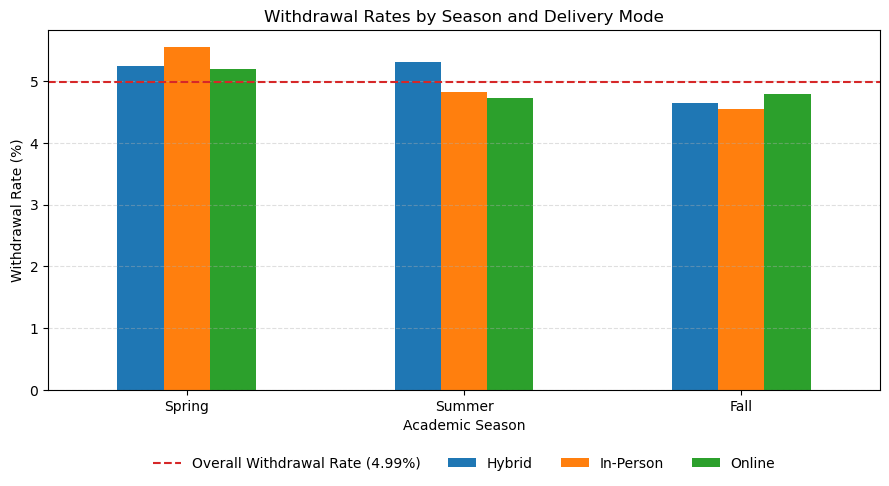

In [208]:
# Interactions between Delivery Mode and Term Season
mode_season_query = """
SELECT
    CASE SUBSTR(CAST(sg.term_code AS TEXT), -2)
        WHEN '01' THEN 'Spring'
        WHEN '05' THEN 'Summer'
        WHEN '08' THEN 'Fall'
    END AS term_season,
    c.delivery_code,
    COUNT(*) AS registrations,
    SUM(sg.withdrawal) AS withdrawals,
    ROUND(AVG(sg.withdrawal) * 100, 2) AS withdrawal_rate
FROM student_grades AS sg
JOIN courses AS c
    ON sg.section_code = c.section_code
    AND sg.term_code = c.term_code
GROUP BY term_season, c.delivery_code
ORDER BY term_season, c.delivery_code;
"""

mode_season_df = pd.read_sql(mode_season_query, engine)

display(mode_season_df)

pivot_df = mode_season_df.pivot(index='term_season', columns='delivery_code', values='withdrawal_rate')
pivot_df = pivot_df.rename(columns={'H': 'Hybrid', 'I': 'In-Person','O': 'Online'})
pivot_df = pivot_df.reindex(['Spring', 'Summer', 'Fall'])
pivot_df.plot(kind='bar',figsize=(9, 5))
plt.title('Withdrawal Rates by Season and Delivery Mode')
plt.xlabel('Academic Season')
plt.ylabel('Withdrawal Rate (%)')
plt.xticks(rotation=0)
plt.axhline(overall_withdrawal_df['average_withdrawal_rate'].iloc[0], color='tab:red', linestyle='--', label='Overall Withdrawal Rate (4.99%)')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Looking at delivery modes within each season shows some differences that weren't apparent in the individual term and mode comparisons. In-person courses have the highest withdrawal rate during spring, hybrid courses during summer, and online courses during fall. There may be a withdrawal patterns that depend on the combination of academic season and delivery mode rather than either characteristic alone.

In [209]:
withdrawal_day_query = """
WITH weekdays AS (
    SELECT 1 AS day_order, 'Monday' AS day
    UNION ALL SELECT 2, 'Tuesday'
    UNION ALL SELECT 3, 'Wednesday'
    UNION ALL SELECT 4, 'Thursday'
    UNION ALL SELECT 5, 'Friday'
    UNION ALL SELECT 6, 'Saturday'
    UNION ALL SELECT 7, 'Sunday'
)

SELECT
    d.day,
    COUNT(*) AS registrations,
    SUM(sg.withdrawal) AS withdrawals,
    ROUND(AVG(sg.withdrawal) * 100, 2) AS withdrawal_rate

FROM student_grades AS sg
JOIN courses AS c
    ON sg.section_code = c.section_code
    AND sg.term_code = c.term_code

CROSS JOIN weekdays AS d

WHERE CASE d.day_order
    WHEN 1 THEN c.monday
    WHEN 2 THEN c.tuesday
    WHEN 3 THEN c.wednesday
    WHEN 4 THEN c.thursday
    WHEN 5 THEN c.friday
    WHEN 6 THEN c.saturday
    WHEN 7 THEN c.sunday
END = 1

GROUP BY d.day_order, d.day
ORDER BY d.day_order;
"""

withdrawal_day_df = pd.read_sql(withdrawal_day_query, engine)
display(withdrawal_day_df)

,day,registrations,withdrawals,withdrawal_rate
0,Monday,25993,1301,5.01
1,Tuesday,18493,908,4.91
2,Wednesday,16807,857,5.10
3,Thursday,21451,1054,4.91
4,Friday,18592,917,4.93
5,Saturday,6224,276,4.43
6,Sunday,2630,133,5.06


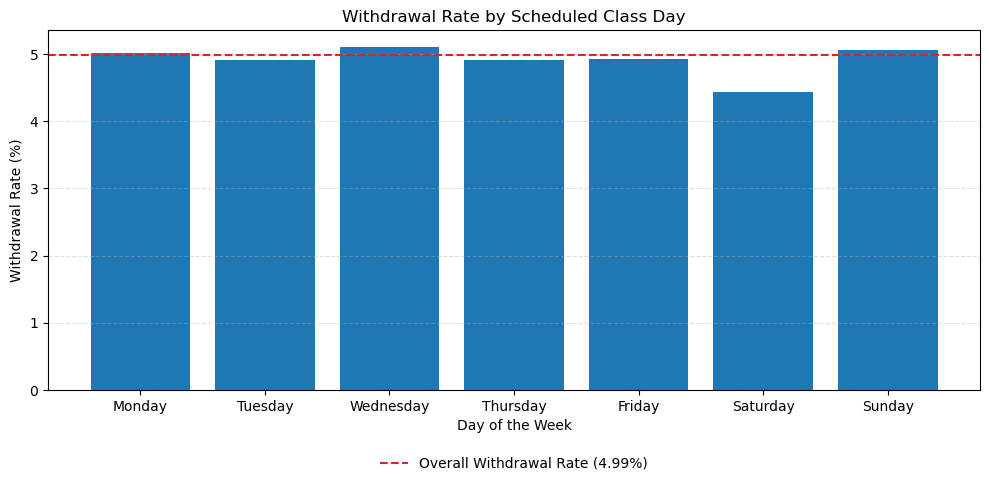

In [210]:
plt.figure(figsize=(10, 5))

plt.bar(
    withdrawal_day_df['day'],
    withdrawal_day_df['withdrawal_rate'],
    color='tab:blue'
)

plt.axhline(
    overall_withdrawal_df['average_withdrawal_rate'].iloc[0],
    color='tab:red',
    linestyle='--',
    label='Overall Withdrawal Rate (4.99%)'
)

plt.title('Withdrawal Rate by Scheduled Class Day')
plt.xlabel('Day of the Week')
plt.ylabel('Withdrawal Rate (%)')

plt.ylim(bottom=0)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.15),
    frameon=False
)

plt.tight_layout()
plt.show()

Withdrawal rates are relatively similar across scheduled class days, ranging from 4.43% on Saturday to 5.10% on Wednesday. There does not appear to be a strong pattern that courses scheduled on a specific day have substantially higher withdrawal rates. Saturday's lower rates could be attributed to the fact that not many classes are offered on Saturday and if they are, they are most likely very needed and students won't withdraw as much. This is, however, just a hypothesis. Further analysis would be needed to verify. 

Additionally, since courses may meet on multiple days, registrations can be counted in more than one weekday group.

### Course-Level Analysis

,major_abbreviation,course_number,registrations,num_sections,withdrawals,withdrawal_rate
0,CHEM,1400,243,1,20,8.23
1,PSY,4090,227,1,18,7.93
2,HIST,4500,139,1,11,7.91
3,CS,1001,133,1,9,6.77
4,ART,1100,789,4,52,6.59
...,...,...,...,...,...,...
77,BIO,2060,533,3,16,3.00
78,ENG,1400,458,2,13,2.84
79,BIO,4090,325,2,9,2.77
80,ENG,1001,268,1,7,2.61


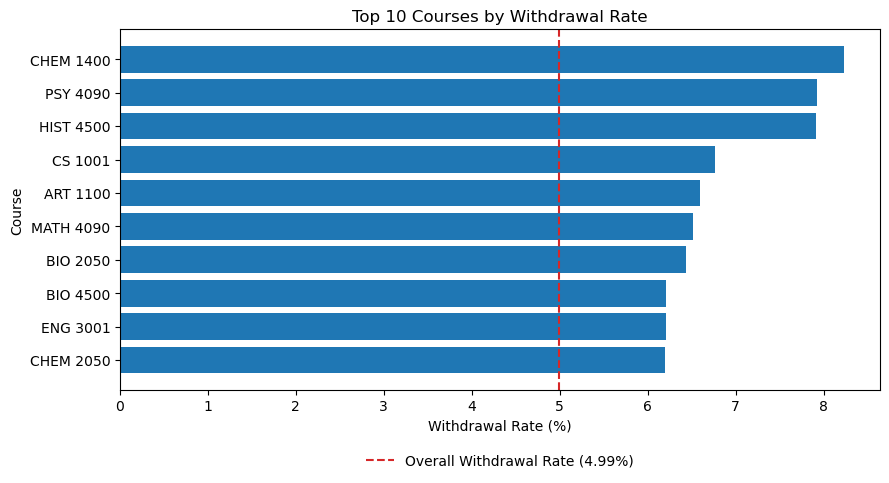

In [211]:
# Withdrawal Rate by Course
withdrawal_course_query = """
SELECT 
    c.major_abbreviation, 
    c.course_number, COUNT(*) AS registrations, 
    COUNT(DISTINCT c.id) AS num_sections,
    SUM(sg.withdrawal) AS withdrawals, 
    ROUND(AVG(sg.withdrawal) * 100, 2) AS withdrawal_rate
FROM student_grades AS sg
JOIN courses AS c ON sg.section_code = c.section_code AND sg.term_code = c.term_code
GROUP BY c.major_abbreviation, c.course_number
ORDER BY withdrawal_rate DESC;
"""

withdrawal_course_df = pd.read_sql(withdrawal_course_query, engine)
display(withdrawal_course_df)


withdrawal_course_df['course'] = (withdrawal_course_df['major_abbreviation'].astype(str) + ' ' + withdrawal_course_df['course_number'].astype(str))

plot_df = withdrawal_course_df.sort_values('withdrawal_rate', ascending=False).head(10)
plt.figure(figsize=(9, 5))
plt.barh(plot_df['course'], plot_df['withdrawal_rate'],color='tab:blue')
plt.gca().invert_yaxis()
plt.axvline(overall_withdrawal_df['average_withdrawal_rate'].iloc[0], color='tab:red', linestyle='--', label='Overall Withdrawal Rate (4.99%)')
plt.xlabel('Withdrawal Rate (%)')
plt.ylabel('Course')
plt.title('Top 10 Courses by Withdrawal Rate')
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.25), frameon=False)
plt.tight_layout()
plt.show()

Withdrawal rates show greater variation across individual courses. CHEM 1400 has the highest observed rate at 8.23%, followed by PSY 4090 (7.93%) and HIST 4500 (7.91%). However, most of these courses each have only one recorded section. It is difficult to determine whether their high rates are attributed to the course itself and whether they are consistent across multiple offerings of the course.

To get a little more insight, only courses offered for more than one terms were analyzed. For each eligible course, the number of sections, terms, delivery modes, registrations, withdrawals, and overall withdrawal rate is calculated.

In [212]:
# Withdrawal Rates for Courses Offered in Multiple Terms
course_summary_query = """
SELECT
    c.major_abbreviation,
    c.course_number,
    COUNT(DISTINCT c.id) AS num_sections,
    COUNT(DISTINCT c.term_code) AS num_terms,
    COUNT(DISTINCT c.delivery_code) AS num_modes,
    COUNT(*) AS registrations,
    SUM(sg.withdrawal) AS withdrawals,
    ROUND(AVG(sg.withdrawal) * 100, 2) AS withdrawal_rate
FROM student_grades AS sg
JOIN courses AS c
    ON sg.section_code = c.section_code
    AND sg.term_code = c.term_code
GROUP BY c.major_abbreviation, c.course_number
HAVING COUNT(DISTINCT c.term_code) >= 2
ORDER BY withdrawal_rate DESC;
"""

course_summary_df = pd.read_sql(course_summary_query, engine)
display(course_summary_df)

,major_abbreviation,course_number,num_sections,num_terms,num_modes,registrations,withdrawals,withdrawal_rate
0,ART,1100,4,4,2,789,52,6.59
1,BIO,4500,3,3,2,676,42,6.21
2,CHEM,2050,3,3,2,548,34,6.20
3,ART,4090,2,2,2,493,30,6.09
4,PSY,2060,6,5,3,1577,96,6.09
5,MATH,2060,3,3,3,881,53,6.02
6,BIO,1001,2,2,2,519,31,5.97
7,MATH,1400,2,2,1,458,27,5.90
8,BIO,3200,3,3,2,854,49,5.74
9,PHYS,4500,2,2,1,805,46,5.71


Among the courses offered across multiple terms, ART 1100 has the highest overall withdrawal rate at 6.59%, with 52 withdrawals across 789 registrations and spanning four terms. Other courses with high rates include BIO 4500 at 6.21%, CHEM 2050 at 6.20%, and ART 4090 and PSY 2060 at 6.0%.

The above courses are examined further to investigate how their withdrawal rates vary across terms and delivery modes in order to see if their withdrawarl trends differ from the average. Several courses were analyzed including the top 5 (ART 1100, BIO 4500, CHEM 2050, ART 4090, PSY 2060) and the bottom 5 (CHEM 1001, CHEM 3200, BIO 2060, ENG 1400, BIO 4090).

In [251]:
# Withdrawal Rate by Term for a Specific Course
selected_major = 'BIO'
selected_course = '4090'

course_term_query = """
SELECT
    c.term_code,
    c.delivery_code,
    COUNT(DISTINCT c.id) AS num_sections,
    COUNT(*) AS registrations,
    SUM(sg.withdrawal) AS withdrawals,
    ROUND(AVG(sg.withdrawal) * 100, 2) AS withdrawal_rate
FROM student_grades AS sg
JOIN courses AS c
    ON sg.section_code = c.section_code
    AND sg.term_code = c.term_code
WHERE c.major_abbreviation = :major AND c.course_number = :course
GROUP BY c.term_code, c.delivery_code
ORDER BY c.term_code;
"""

course_term_df = pd.read_sql(course_term_query, engine, params={'major': selected_major, 'course': selected_course})
display(course_term_df)

,term_code,delivery_code,num_sections,registrations,withdrawals,withdrawal_rate
0,201905,I,1,190,6,3.16
1,201908,O,1,135,3,2.22


,term_code,registrations,withdrawals,withdrawal_rate_course,withdrawal_rate_overall,difference_pp
0,201905,190,6,3.16,4.88,-1.72
1,201908,135,3,2.22,4.95,-2.73


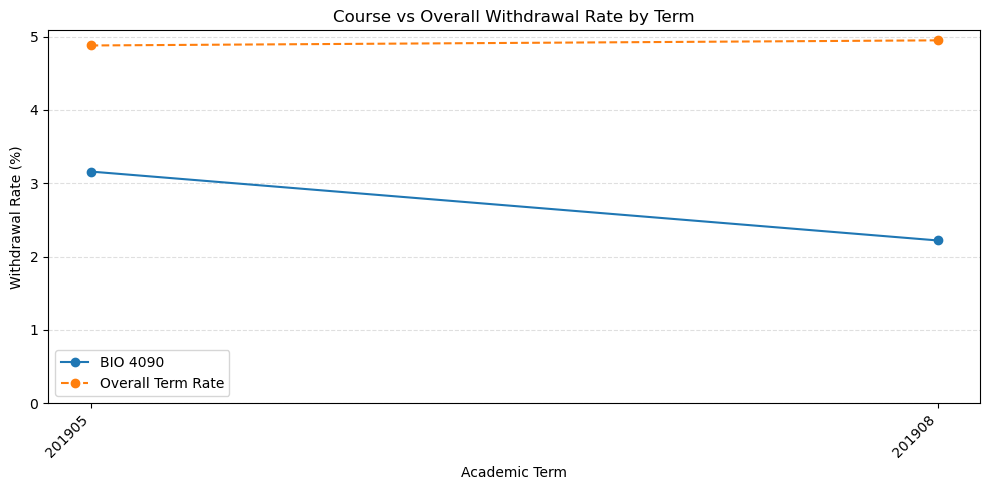

In [252]:
course_by_term_df = (course_term_df.groupby('term_code', as_index=False).agg(registrations=('registrations', 'sum'), withdrawals=('withdrawals', 'sum')))

course_by_term_df['withdrawal_rate'] = (course_by_term_df['withdrawals'] / course_by_term_df['registrations'] * 100).round(2)

term_comparison_df = course_by_term_df.merge(withdrawal_term_df[['term_code', 'withdrawal_rate']], on='term_code', suffixes=('_course', '_overall'))
term_comparison_df['difference_pp'] = (term_comparison_df['withdrawal_rate_course'] - term_comparison_df['withdrawal_rate_overall']).round(2)

display(term_comparison_df)

plt.figure(figsize=(10, 5))
plt.plot(term_comparison_df['term_code'].astype(str), term_comparison_df['withdrawal_rate_course'], marker='o', label=f'{selected_major} {selected_course}')
plt.plot(term_comparison_df['term_code'].astype(str), term_comparison_df['withdrawal_rate_overall'], marker='o', linestyle='--', label='Overall Term Rate')
plt.title('Course vs Overall Withdrawal Rate by Term')
plt.xlabel('Academic Term')
plt.ylabel('Withdrawal Rate (%)')
plt.ylim(bottom=0)
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [253]:
# Withdrawal Rate by Delivery Mode for the Same Specific Course
course_mode_df = (course_term_df.groupby('delivery_code', as_index=False).agg(num_terms=('term_code', 'nunique'), registrations=('registrations', 'sum'), withdrawals=('withdrawals', 'sum')))

course_mode_df['withdrawal_rate'] = (course_mode_df['withdrawals'] / course_mode_df['registrations'] * 100).round(2)

course_mode_df = course_mode_df.merge(withdrawal_mode_df[['delivery_code', 'withdrawal_rate']], on='delivery_code', suffixes=('_course', '_overall'))

course_mode_df['difference_pp'] = (course_mode_df['withdrawal_rate_course'] - course_mode_df['withdrawal_rate_overall']).round(2)

display(course_mode_df)

,delivery_code,num_terms,registrations,withdrawals,withdrawal_rate_course,withdrawal_rate_overall,difference_pp
0,I,1,190,6,3.16,5.01,-1.85
1,O,1,135,3,2.22,4.87,-2.65


Top 1: **ART 1100 (6.59%)**

ART 1100 had withdrawal rates above the overall average rate for all four terms in which it was offered. This suggest that there might be a pattern for high withdrawals in this course. Its rate is also increasing more than the average over the terms. Its in-person withdrawal rate (6.78%) was higher than its hybrid rate (5.41%) but the sections were not offered in the same term so it is hard to compare.

Top 2: **BIO 4500 (6.21%)**

BIO 4500 also had withdrawal rates above the average rate for its three terms, increasing from 4.40% in Fall 2022 to 7.53% in Summer 2024. Its trend shows a widening gap but follow the shape of the average better than ART 1100. In-person sections also had a higher withdrawal rate (7.28%) than the hybrid section (4.40%). However, once again, since the delivery modes were offered in different terms, it is difficult to determine whether this difference is related to delivery format or term-specific factors.

Top 3: **CHEM 2050 (6.20%)**

CHEM 2050 showed surprising variability across its three terms. Its withdrawal rate increased from 4.43% in Summer 2019 to 10.34% in Fall 2019 before declining to 5.47% in Fall 2020. The Fall 2019 rate was notably high, exceeding the average rate by 5.39 percentage points and deviating massively from the overall withdrawal trend. If further analysis were to be done, the Fall 2019 observation for this course is worth noting to investigate if there was a specific reason or event that drove the high withdrawal in that term for this course. In-person sections also had a higher withdrawal rate (6.92%) than the online section (4.43%) but again, the different delivery modes were offered in different terms, limiting direct comparisons.

Top 4: **ART 4090 (6.09%)**

ART 4090 had withdrawal rates above the average rate in both its terms. Its rate decreased slightly from 6.43% in Summer 2020 to 5.74% in Summer 2021. The decline, however, was consistent with the overall withdrawal trend with a gap of approximately 1.2-1.4 percentage points. The hybrid section had a slightly higher withdrawal rate than the in-person section but it is not a direct comparison either. This course also has only two terms so not much can be concluded.

Top 5: **PSY 2060 (6.09%)**

PSY 2060 had withdrawal rates above the overall rate in all five terms, although the differences varied more than other courses. The largest gaps are in Spring 2021 and Summer 2024. Spring 2023 was nearly identical to the overall rate. Online sections had a higher withdrawal rate (7.09%) than in-person (5.41%) and hybrid (5.35%) sections but it might be attributted to term-specific factors.

**Bottom Five Courses (2.77% - 3.64%)**

All five courses consistently had withdrawal rates below the overall average rates across all terms and modes. Although individual rates fluctuated, particularly for BIO 2060, none of them exceeded the term average rate and their trend sometimes was opposite the average trend. Their lower rates may not be as driven by term-specific factors. Similar to the top 5 courses, delivery modes varied across terms and each course had relatively few observed offerings. So, further analysis would be needed to understand the factors behind these differences.

### Instructor Analysis

In [216]:
# Withdrawal Rate by Instructor
withdrawal_instructor_query = """
SELECT
    i.employee_id,
    i.first_name,
    i.last_name,
    COUNT(DISTINCT c.id) AS sections_taught,
    COUNT(*) AS registrations,
    SUM(sg.withdrawal) AS withdrawals,
    ROUND(AVG(sg.withdrawal) * 100, 2) AS withdrawal_rate
FROM student_grades AS sg
JOIN courses AS c
    ON sg.section_code = c.section_code
    AND sg.term_code = c.term_code
JOIN instructor_main AS i
    ON c.employee_id = i.employee_id
GROUP BY
    i.employee_id,
    i.first_name,
    i.last_name
ORDER BY withdrawal_rate DESC;
"""

withdrawal_instructor_df = pd.read_sql(withdrawal_instructor_query, engine)
display(withdrawal_instructor_df)

,employee_id,first_name,last_name,sections_taught,registrations,withdrawals,withdrawal_rate
0,34542,Amy,Vasquez,1,243,20,8.23
1,69971,Grant,Bowen,2,526,38,7.22
2,71740,Rebecca,Lopez,1,241,17,7.05
3,76996,Nancy,Garcia,1,213,15,7.04
4,13662,Tiffany,Davis,1,206,14,6.80
...,...,...,...,...,...,...,...
83,85240,Sean,Lowery,1,199,6,3.02
84,90230,Patrick,Jenkins,1,266,8,3.01
85,87146,Amanda,Castro,1,235,7,2.98
86,66370,Jasmine,Leblanc,2,311,9,2.89


Withdrawal rates also vary across instructors. Amy Vasquez has the highest observed rate at 8.23%. However, this rate comes from a single section of CHEM 1400, which also has an 8.23% withdrawal rate. Hence, there is a limitation with comparing instructors' withdrawal rates. An instructor's rate may be closely associated with the particular course they teach more than the instructor themselves. Instructor withdrawal rankings are insufficient to determine whether differences in withdrawal rates are attributable to individual instructors.

For a more meaningful and comparable analysis, the next part looks for courses with multiple sections taught by different instructors within the same course and term.

In [217]:
section_coverage_query = """
WITH course_terms AS (
    SELECT
        major_abbreviation,
        course_number,
        term_code,
        COUNT(DISTINCT id) AS num_sections,
        COUNT(DISTINCT employee_id) AS num_instructors
    FROM courses
    GROUP BY
        major_abbreviation,
        course_number,
        term_code
)
SELECT
    COUNT(*) AS total_course_terms,
    SUM(CASE WHEN num_sections = 1
        THEN 1 ELSE 0 END) AS single_section,
    SUM(CASE WHEN num_sections > 1
        THEN 1 ELSE 0 END) AS multiple_sections,
    SUM(CASE WHEN num_instructors > 1
        THEN 1 ELSE 0 END) AS multiple_instructors
FROM course_terms;
"""

section_coverage_df = pd.read_sql(
    section_coverage_query, engine
)

display(section_coverage_df)

,total_course_terms,single_section,multiple_sections,multiple_instructors
0,189,178,11,11


In [218]:
comparable_courses_query = """
SELECT
    c.major_abbreviation,
    c.course_number,
    c.term_code,
    COUNT(DISTINCT c.id) AS num_sections,
    COUNT(DISTINCT c.employee_id) AS num_instructors,
    COUNT(DISTINCT c.delivery_code) AS num_modes
FROM courses AS c
GROUP BY
    c.major_abbreviation,
    c.course_number,
    c.term_code
HAVING COUNT(DISTINCT c.id) > 1
    AND COUNT(DISTINCT c.employee_id) > 1
ORDER BY num_sections DESC;
"""

comparable_courses_df = pd.read_sql(
    comparable_courses_query, engine
)

display(comparable_courses_df)

,major_abbreviation,course_number,term_code,num_sections,num_instructors,num_modes
0,CHEM,4500,201908,2,2,2
1,CS,1100,202208,2,2,1
2,CS,2060,201908,2,2,2
3,ECON,2060,202101,2,2,2
4,ENG,1100,201901,2,2,2
5,ENG,2060,202005,2,2,1
6,HIST,1001,201908,2,2,2
7,HIST,3001,202405,2,2,2
8,MATH,3001,202308,2,2,2
9,PHYS,2050,202105,2,2,1


In [254]:
same_mode_df = comparable_courses_df[
    comparable_courses_df['num_modes'] == 1
].reset_index(drop=True)

display(same_mode_df)

,major_abbreviation,course_number,term_code,num_sections,num_instructors,num_modes
0,CS,1100,202208,2,2,1
1,ENG,2060,202005,2,2,1
2,PHYS,2050,202105,2,2,1
3,PSY,2060,202405,2,2,1


Of 189 course-term combinations, 178 (94.2%) have only one section. Only 11 courses have multiple sections taught by different instructors, and just four share the same delivery mode across sections.

This considerably limits meaningful instructor comparisons. Still, the following analyzes those four courses for any potential insights.

In [258]:
selected = same_mode_df.iloc[3]

selected_major = selected['major_abbreviation']
selected_course = str(selected['course_number'])
selected_term = int(selected['term_code'])

instructor_comparison_query = """
SELECT
    c.major_abbreviation,
    c.course_number,
    c.term_code,
    c.section_code,
    i.first_name || ' ' || i.last_name AS instructor,
    c.delivery_code,
    c.time,
    CASE 
        WHEN monday = 1 THEN 'monday'
        WHEN tuesday = 1 THEN 'tuesday'
        WHEN wednesday = 1 THEN 'wednesday'
        WHEN thursday = 1 THEN 'thursday'
        WHEN friday = 1 THEN 'friday'
        WHEN saturday = 1 THEN 'saturday'
        WHEN sunday = 1 THEN 'sunday'
        ELSE 'None'
    END AS day_of_week,
    COUNT(sg.id) AS registrations,
    SUM(sg.withdrawal) AS withdrawals,
    ROUND(AVG(sg.withdrawal) * 100, 2) AS withdrawal_rate
FROM courses AS c
JOIN student_grades AS sg
    ON c.section_code = sg.section_code
    AND c.term_code = sg.term_code
JOIN instructor_main AS i
    ON c.employee_id = i.employee_id
WHERE
    c.major_abbreviation = :major
    AND CAST(c.course_number AS TEXT) = :course
    AND c.term_code = :term
GROUP BY c.id
ORDER BY withdrawal_rate DESC;
"""

instructor_comparison_df = pd.read_sql(instructor_comparison_query, engine, params={'major': selected_major, 'course': selected_course, 'term': selected_term})
display(instructor_comparison_df)

,major_abbreviation,course_number,term_code,section_code,instructor,delivery_code,time,day_of_week,registrations,withdrawals,withdrawal_rate
0,PSY,2060,202405,82525,Cynthia Hernandez,O,17:30,wednesday,202,15,7.43
1,PSY,2060,202405,52848,Tiffany Davis,O,20:30,thursday,206,14,6.80


Across the four courses offered in the same term with the same delivery but different instructors, withdrawal rates were generally similar between instructors. CS 1100 showed almost identical rates (3.56% vs. 3.54%). PHYS 2050 and PSY 2060 had relatively small differences of about 0.50 and 0.63 percentage points, respectively. ENG 2060 showed the largest difference at 1.28 percentage points (6.61% vs. 5.33%).

Although comparing the same course, term, and delivery mode provides a more consistent and comparable basis for analysis, the sections still have differences such as class time and day. Additionally, each comparison includes only two sections so it is difficult to determine whether these differences actually reflect instructor-related attributes. Overall, the results does not really tell much about instructor effectiveness and influence.

### Conclusion & Limitations

All in all, withdrawal rates do exhibit some variations across academic terms, delivery modes, and courses. There appears to be more withdrawals in Spring semesters and slightly more for Hybrid courses. At the course level, certain courses were consistently exceeding the university-wide withdrawal rate across its terms. CHEM 2050 had unusual withdrawal rate trend, making it a potential candidate for further investigation.

However, due to the limited data, most courses have only one observation and it is not possible to truly establish recurring patterns nor causations. Differences in withdrawal rates may reflect course difficulty, student characteristics, scheduling, or other factors that were not examined. Likewise, the limited number of comparable sections makes it difficult to isolate instructor-related differences.

Given more detailed student and course data, future analysis could investigate why certain terms, modes, courses, and instructors have higher withdrawal rates and whether additional academic support or course management may be beneficial.

# Finish

### Submission Instructions
Once you are finished with the analysis, please save the notebook and email the link to Isaac at ikerson@gsu.edu. If you have any questions or need assistance, feel free to contact Isaac.

We appreciate your time and effort. Good luck, and we look forward to discussing your work!